# 实验二： 使用SARSA、Q-learning解决悬崖寻路问题

**姓名：** 

刘乐

**学号：** 

26120258

## 实验目的

* 分别利用 SARSA 算法和 Q-learning 算法寻找悬崖寻路问题中的最优策略；
* 掌握 SARSA、Q-learning 算法的区别及其核心环节。

## 1. SARSA、Q-learning 算法流程

### Sarsa:  An on-policy TD control algorithm

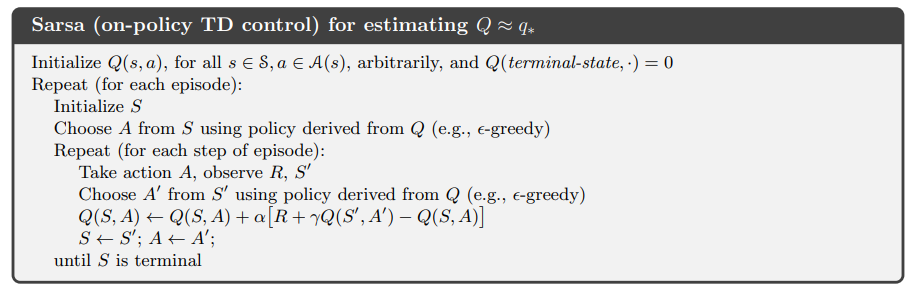

### Q-learning: An off-policy TD control algorithm

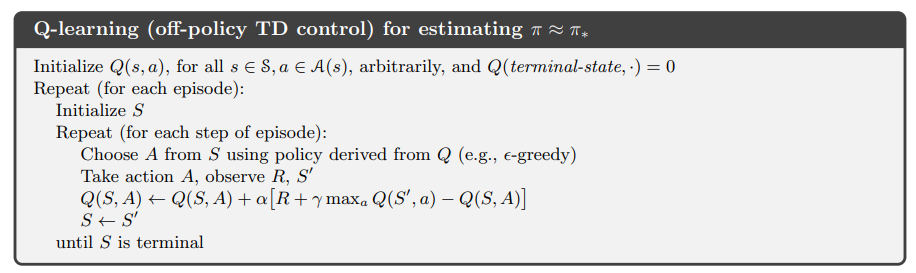

## 2. 环境介绍

该环境名叫悬崖寻路问题，是指在一个4 x 12的网格中，智能体以网格的左下角位置为起点，以网格的下角位置为终点，目标是移动智能体到达终点位置，智能体每次可以在上、下、左、右这4个方向中移动一步，每移动一步会得到-1单位的奖励。

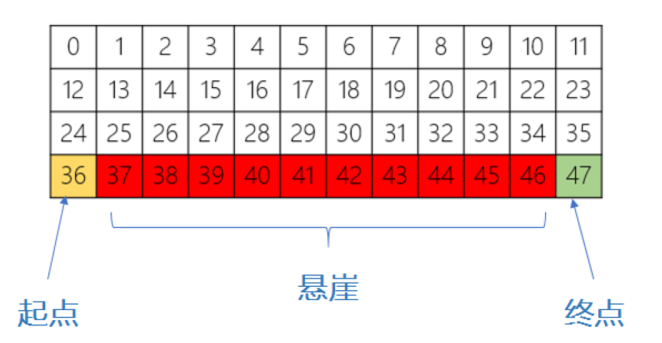

如图，红色部分表示悬崖，数字代表智能体能够观测到的位置信息，即observation，总共会有0-47等48个不同的值，智能体再移动中会有以下限制：

* 智能体不能移出网格，如果智能体想执行某个动作移出网格，那么这一步智能体不会移动，但是这个操作依然会得到-1单位的奖励

* 如果智能体“掉入悬崖” ，会立即回到起点位置，并得到-100单位的奖励

* 当智能体移动到终点时，该回合结束，该回合总奖励为各步奖励之和

实际的仿真界面如下：

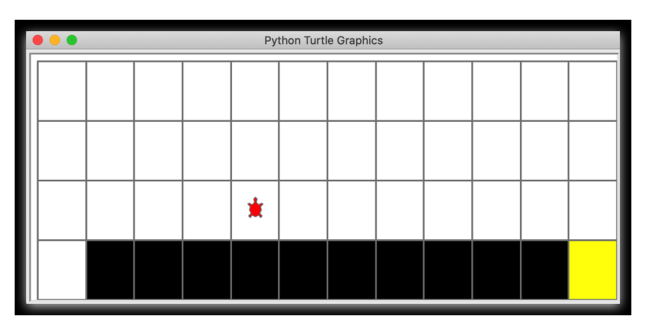

由于从起点到终点最少需要**13**步，每步得到 **-1** 的reward，因此最佳训练算法下，每个episode下reward总和应该为 **-13**。所以我们的目标也是要通过RL训练出一个模型，使得该模型能在测试中一个episode的reward能够接近于 **-13** 左右。

## 3. RL任务训练

### 3.1 本次实验所需要引入的包

In [41]:
import numpy as np
import math
import torch
from collections import defaultdict
import gymnasium as gym
import turtle
import argparse
import matplotlib.pyplot as plt
import seaborn as sns

如果缺少哪个，直接用以下命令安装即可

```python
pip install (缺失包的名称)

```

### 3.2. 环境创建初始化

In [42]:
class CliffWalkingWapper(gym.Wrapper):
    def __init__(self, env):
        gym.Wrapper.__init__(self, env)
        self.t = None
        self.unit = 50
        self.max_x = 12
        self.max_y = 4

    def draw_x_line(self, y, x0, x1, color='gray'):
        assert x1 > x0
        self.t.color(color)
        self.t.setheading(0)
        self.t.up()
        self.t.goto(x0, y)
        self.t.down()
        self.t.forward(x1 - x0)

    def draw_y_line(self, x, y0, y1, color='gray'):
        assert y1 > y0
        self.t.color(color)
        self.t.setheading(90)
        self.t.up()
        self.t.goto(x, y0)
        self.t.down()
        self.t.forward(y1 - y0)

    def draw_box(self, x, y, fillcolor='', line_color='gray'):
        self.t.up()
        self.t.goto(x * self.unit, y * self.unit)
        self.t.color(line_color)
        self.t.fillcolor(fillcolor)
        self.t.setheading(90)
        self.t.down()
        self.t.begin_fill()
        for i in range(4):
            self.t.forward(self.unit)
            self.t.right(90)
        self.t.end_fill()

    def move_player(self, x, y):
        self.t.up()
        self.t.setheading(90)
        self.t.fillcolor('red')
        self.t.goto((x + 0.5) * self.unit, (y + 0.5) * self.unit)

    def render(self):
        if self.t == None:
            self.t = turtle.Turtle()
            self.wn = turtle.Screen()
            self.wn.setup(self.unit * self.max_x + 100,
                          self.unit * self.max_y + 100)
            self.wn.setworldcoordinates(0, 0, self.unit * self.max_x,
                                        self.unit * self.max_y)
            self.t.shape('circle')
            self.t.width(2)
            self.t.speed(0)
            self.t.color('gray')
            for _ in range(2):
                self.t.forward(self.max_x * self.unit)
                self.t.left(90)
                self.t.forward(self.max_y * self.unit)
                self.t.left(90)
            for i in range(1, self.max_y):
                self.draw_x_line(
                    y=i * self.unit, x0=0, x1=self.max_x * self.unit)
            for i in range(1, self.max_x):
                self.draw_y_line(
                    x=i * self.unit, y0=0, y1=self.max_y * self.unit)

            for i in range(1, self.max_x - 1):
                self.draw_box(i, 0, 'black')
            self.draw_box(self.max_x - 1, 0, 'yellow')
            self.t.shape('turtle')

        x_pos = self.unwrapped.s % self.max_x
        y_pos = self.max_y - 1 - int(self.unwrapped.s / self.max_x)
        self.move_player(x_pos, y_pos)

### 3.3 画出结果曲线所需要的工具定义

In [43]:
def smooth(data, weight=0.9):  
    '''用于平滑曲线，类似于Tensorboard中的smooth

    Args:
        data (List):输入数据
        weight (Float): 平滑权重，处于0-1之间，数值越高说明越平滑，一般取0.9

    Returns:
        smoothed (List): 平滑后的数据
    '''
    last = data[0]  # First value in the plot (first timestep)
    smoothed = list()
    for point in data:
        smoothed_val = last * weight + (1 - weight) * point  # 计算平滑值
        smoothed.append(smoothed_val)                    
        last = smoothed_val                                
    return smoothed

def plot_rewards(rewards,cfg, tag='train'):
    sns.set()
    plt.figure()  # 创建一个图形实例，方便同时多画几个图
    plt.title("learning curve on {} of {} for {}".format(
        cfg.device, cfg.algo_name, cfg.env_name))
    plt.xlabel('epsiodes')
    plt.plot(rewards, label='rewards')
    plt.plot(smooth(rewards), label='smoothed')
    plt.legend()
    plt.show()

## 3.4 SARSA

### 3.4.1 相关参数设定

In [44]:
parser = argparse.ArgumentParser(description="hyperparameters") 
parser.add_argument('--algo_name',default='Sarsa',type=str,help="name of algorithm")# 算法名称
parser.add_argument('--env_name',default='CliffWalking-v1',type=str,help="name of environment")
parser.add_argument('--train_eps',default=400,type=int,help="episodes of training") # 训练的回合数
parser.add_argument('--test_eps',default=20,type=int,help="episodes of testing") # 测试的回合数
parser.add_argument('--gamma',default=0.90,type=float,help="discounted factor") # 折扣因子
parser.add_argument('--epsilon',default=0.3,type=float,help="initial value of epsilon") #  e-greedy策略中初始epsilon
parser.add_argument('--lr',default=0.1,type=float,help="learning rate")
parser.add_argument('--device',default='cpu',type=str,help="cpu or cuda")
parser.add_argument('--seed',default=26120258,type=int,help="random seed")
cfg = parser.parse_args([])

### 3.4.2 SARSA 主要代码框架

In [45]:
class Sarsa(object):
    def __init__(self,
                 n_actions,cfg):
        self.n_actions = n_actions  
        self.lr = cfg.lr  
        self.gamma = cfg.gamma  
        self.sample_count = 0 
        self.epsilon = cfg.epsilon
        self.Q  = defaultdict(lambda: np.zeros(n_actions)) # Q table
    def sample(self, state):
        self.sample_count += 1
        best_action = np.argmax(self.Q[state])
        action_probs = np.ones(self.n_actions, dtype=float) * self.epsilon / self.n_actions
        action_probs[best_action] += (1.0 - self.epsilon)
        action = np.random.choice(np.arange(len(action_probs)), p=action_probs)
        return action
    def predict(self,state):
        return np.argmax(self.Q[state])
    def update(self, state, action, reward, next_state, next_action,done):
        Q_predict = self.Q[state][action]  # 获得当前预测Q值
        if done:
            Q_target = reward  # 终止状态不再考虑未来奖励
        else: 
            #与 Q-learning不同，Sarsa是拿下一步动作对应的Q值去更新
            Q_target = reward + self.gamma * self.Q[next_state][next_action]
            
        self.Q[state][action] += self.lr * (Q_target - Q_predict) 

In [46]:
def env_agent_config(cfg,seed=1):
    '''创建环境和智能体
    Args:
        cfg ([type]): [description]
        seed (int, optional): 随机种子. Defaults to 1.
    Returns:
        env [type]: 环境
        agent : 智能体
    '''    
    seed = cfg.seed
    np.random.seed(seed)
    
    env = gym.make(cfg.env_name)  
    env = CliffWalkingWapper(env)
    env.reset(seed=seed) # 设置随机种子并初始化环境
    n_states = env.observation_space.n # 状态维度
    n_actions = env.action_space.n # 动作维度
    print(f"状态数：{n_states}，动作数：{n_actions}")
    agent = Sarsa(n_actions,cfg)
    return env,agent

In [47]:
env, agent = env_agent_config(cfg)

状态数：48，动作数：4


### 3.4.3 开始训练

In [48]:
print('开始训练！')
print(f'环境:{cfg.env_name}, 算法:{cfg.algo_name}, 设备:{cfg.device}')
train_rewards = []  # 记录奖励
for i_ep in range(cfg.train_eps):
    ep_reward = 0  # 记录每个回合的奖励
    state, _ = env.reset()  # 重置环境,即开始新的回合
    action = agent.sample(state)
    while True:
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated  # 到达终点或回合被截断时结束
        next_action = agent.sample(next_state)
        agent.update(state, action, reward, next_state, next_action, terminated) # 算法更新
        state = next_state # 更新状态
        action = next_action
        ep_reward += reward
        if done:
            break
    train_rewards.append(ep_reward)
    print(f"回合：{i_ep+1}/{cfg.train_eps}，奖励：{ep_reward:.1f}，Epsilon：{agent.epsilon}")
print('完成训练！')
    

开始训练！
环境:CliffWalking-v1, 算法:Sarsa, 设备:cpu
回合：1/400，奖励：-2139.0，Epsilon：0.3
回合：2/400，奖励：-2260.0，Epsilon：0.3
回合：3/400，奖励：-605.0，Epsilon：0.3
回合：4/400，奖励：-817.0，Epsilon：0.3
回合：5/400，奖励：-153.0，Epsilon：0.3
回合：6/400，奖励：-57.0，Epsilon：0.3
回合：7/400，奖励：-318.0，Epsilon：0.3
回合：8/400，奖励：-842.0，Epsilon：0.3
回合：9/400，奖励：-109.0，Epsilon：0.3
回合：10/400，奖励：-621.0，Epsilon：0.3
回合：11/400，奖励：-67.0，Epsilon：0.3
回合：12/400，奖励：-151.0，Epsilon：0.3
回合：13/400，奖励：-85.0，Epsilon：0.3
回合：14/400，奖励：-600.0，Epsilon：0.3
回合：15/400，奖励：-118.0，Epsilon：0.3
回合：16/400，奖励：-163.0，Epsilon：0.3
回合：17/400，奖励：-96.0，Epsilon：0.3
回合：18/400，奖励：-200.0，Epsilon：0.3
回合：19/400，奖励：-43.0，Epsilon：0.3
回合：20/400，奖励：-406.0，Epsilon：0.3
回合：21/400，奖励：-103.0，Epsilon：0.3
回合：22/400，奖励：-78.0，Epsilon：0.3
回合：23/400，奖励：-94.0，Epsilon：0.3
回合：24/400，奖励：-149.0，Epsilon：0.3
回合：25/400，奖励：-77.0，Epsilon：0.3
回合：26/400，奖励：-476.0，Epsilon：0.3
回合：27/400，奖励：-184.0，Epsilon：0.3
回合：28/400，奖励：-41.0，Epsilon：0.3
回合：29/400，奖励：-380.0，Epsilon：0.3
回合：30/400，奖励：-43.0，Epsilon：0.3
回合：31/400，奖励：-

### 3.4.4 画出训练结果图

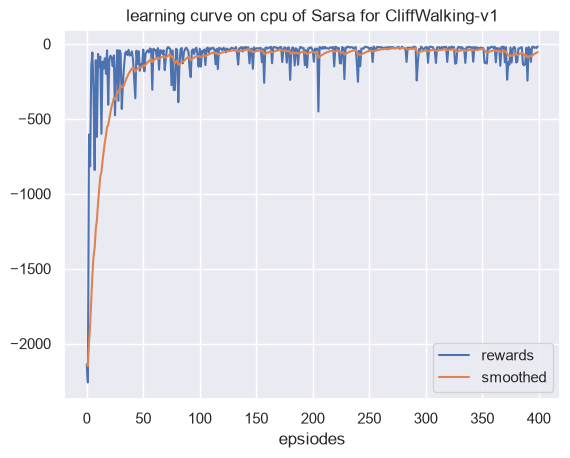

In [49]:
plot_rewards(train_rewards, cfg, tag="train")  

### 3.4.5 开始测试

In [50]:
print('开始测试！')
print(f'环境：{cfg.env_name}, 算法：{cfg.algo_name}, 设备：{cfg.device}')
test_rewards = []  # 记录所有回合的奖励
for i_ep in range(cfg.test_eps):
    ep_reward = 0  # 记录每个episode的reward
    state, _ = env.reset()  # 重置环境, 重新开一局（即开始新的一个回合）
    while True:
        action = agent.predict(state)  # 根据算法选择一个动作
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        state = next_state  # 更新状态
        ep_reward += reward
#         env.render() #windows 平台的同学和Linux有外界显示器的，可以尝试渲染
        if done:
            break
    test_rewards.append(ep_reward)
    print(f"回合数：{i_ep+1}/{cfg.test_eps}, 奖励：{ep_reward:.1f}")
print('完成测试！')

开始测试！
环境：CliffWalking-v1, 算法：Sarsa, 设备：cpu
回合数：1/20, 奖励：-17.0
回合数：2/20, 奖励：-17.0
回合数：3/20, 奖励：-17.0
回合数：4/20, 奖励：-17.0
回合数：5/20, 奖励：-17.0
回合数：6/20, 奖励：-17.0
回合数：7/20, 奖励：-17.0
回合数：8/20, 奖励：-17.0
回合数：9/20, 奖励：-17.0
回合数：10/20, 奖励：-17.0
回合数：11/20, 奖励：-17.0
回合数：12/20, 奖励：-17.0
回合数：13/20, 奖励：-17.0
回合数：14/20, 奖励：-17.0
回合数：15/20, 奖励：-17.0
回合数：16/20, 奖励：-17.0
回合数：17/20, 奖励：-17.0
回合数：18/20, 奖励：-17.0
回合数：19/20, 奖励：-17.0
回合数：20/20, 奖励：-17.0
完成测试！


### 3.4.6 画出测试结果图

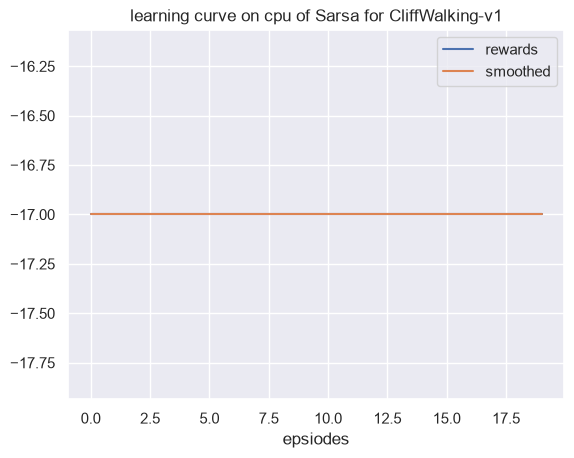

In [51]:
plot_rewards(test_rewards, cfg, tag="train")  

## 3.5 Q-Learning

### 3.5.1 相关参数设定

In [52]:
parser = argparse.ArgumentParser(description="hyperparameters") 
parser.add_argument('--algo_name',default='Q-learning',type=str,help="name of algorithm")
parser.add_argument('--env_name',default='CliffWalking-v1',type=str,help="name of environment")
parser.add_argument('--train_eps',default=400,type=int,help="episodes of training") # 训练的回合数
parser.add_argument('--test_eps',default=20,type=int,help="episodes of testing") # 测试的回合数
parser.add_argument('--gamma',default=0.90,type=float,help="discounted factor") # 折扣因子
parser.add_argument('--epsilon',default=0.3,type=float,help="initial value of epsilon") #  e-greedy策略中初始epsilon
parser.add_argument('--lr',default=0.1,type=float,help="learning rate")
parser.add_argument('--device',default='cpu',type=str,help="cpu or cuda")
parser.add_argument('--seed',default=26120258,type=int,help="random seed")
cfg = parser.parse_args([])

### 3.5.2 QLearning 主要代码框架

In [53]:
class QLearning(object):
    def __init__(self,n_states,
                 n_actions,cfg):
        self.n_actions = n_actions 
        self.lr = cfg.lr  # 学习率
        self.gamma = cfg.gamma  
        self.epsilon = cfg.epsilon
        self.sample_count = 0  
        self.Q_table  = defaultdict(lambda: np.zeros(n_actions)) # 用嵌套字典存放状态->动作->状态-动作值（Q值）的映射，即Q表
    def sample(self, state):
        ''' 采样动作，训练时用
        '''
        self.sample_count += 1
        # e-greedy 策略
        if np.random.uniform(0, 1) > self.epsilon:
            # 选择Q(s,a)最大对应的动作， 通过查询Q表，选取在当前状态下Q值最大的动作
            action = np.argmax(self.Q_table[str(state)])
            
        else:
            # 随机选择动作
            action = np.random.choice(self.n_actions)
            
            
        return action
    def predict(self,state):
        ''' 预测或选择动作，测试时用
        '''
        action = np.argmax(self.Q_table[str(state)])
        return action
    def update(self, state, action, reward, next_state, done): 
        '''
        基于采样得到的历史数据更新Q表
        '''
        Q_predict = self.Q_table[str(state)][action]  # 获得当前预测Q值
        if done: # 终止状态
            Q_target = reward
        else:
            # Q-learning是拿下一步中奖励最大的动作作为当前Q值的target进行更新
            Q_target = reward + self.gamma * np.max(self.Q_table[str(next_state)])

            
        self.Q_table[str(state)][action] += self.lr * (Q_target - Q_predict)

In [54]:
def env_agent_config(cfg,seed=1):
    '''创建环境和智能体
    Args:
        cfg ([type]): [description]
        seed (int, optional): 随机种子. Defaults to 1.
    Returns:
        env [type]: 环境
        agent : 智能体
    '''  
    seed=cfg.seed  
    np.random.seed(seed)
    
    env = gym.make(cfg.env_name)  
    env = CliffWalkingWapper(env)
    env.reset(seed=seed) # 设置随机种子并初始化环境
    n_states = env.observation_space.n # 状态维度
    n_actions = env.action_space.n # 动作维度
    agent = QLearning(n_states,n_actions,cfg)
    return env,agent

In [55]:
env, agent = env_agent_config(cfg)

### 3.5.3 开始训练

In [56]:
print('开始训练！')
print(f'环境:{cfg.env_name}, 算法:{cfg.algo_name}, 设备:{cfg.device}')
train_rewards = []  # 记录奖励
for i_ep in range(cfg.train_eps):
    ep_reward = 0  # 记录每个回合的奖励
    state, _ = env.reset()  # 重置环境,即开始新的回合
    while True:
        action = agent.sample(state)  # 根据算法采样一个动作
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        agent.update(state, action, reward, next_state, terminated)  # Q学习算法更新
        state = next_state  # 更新状态
        ep_reward += reward
        if done:
            break
    train_rewards.append(ep_reward)
    print(f"回合：{i_ep+1}/{cfg.train_eps}，奖励：{ep_reward:.1f}，Epsilon：{agent.epsilon}")
print('完成训练！')

开始训练！
环境:CliffWalking-v1, 算法:Q-learning, 设备:cpu
回合：1/400，奖励：-562.0，Epsilon：0.3
回合：2/400，奖励：-5559.0，Epsilon：0.3
回合：3/400，奖励：-452.0，Epsilon：0.3
回合：4/400，奖励：-1720.0，Epsilon：0.3
回合：5/400，奖励：-145.0，Epsilon：0.3
回合：6/400，奖励：-535.0，Epsilon：0.3
回合：7/400，奖励：-1299.0，Epsilon：0.3
回合：8/400，奖励：-742.0，Epsilon：0.3
回合：9/400，奖励：-939.0，Epsilon：0.3
回合：10/400，奖励：-494.0，Epsilon：0.3
回合：11/400，奖励：-483.0，Epsilon：0.3
回合：12/400，奖励：-467.0，Epsilon：0.3
回合：13/400，奖励：-50.0，Epsilon：0.3
回合：14/400，奖励：-496.0，Epsilon：0.3
回合：15/400，奖励：-219.0，Epsilon：0.3
回合：16/400，奖励：-57.0，Epsilon：0.3
回合：17/400，奖励：-168.0，Epsilon：0.3
回合：18/400，奖励：-571.0，Epsilon：0.3
回合：19/400，奖励：-902.0，Epsilon：0.3
回合：20/400，奖励：-471.0，Epsilon：0.3
回合：21/400，奖励：-370.0，Epsilon：0.3
回合：22/400，奖励：-169.0，Epsilon：0.3
回合：23/400，奖励：-61.0，Epsilon：0.3
回合：24/400，奖励：-69.0，Epsilon：0.3
回合：25/400，奖励：-114.0，Epsilon：0.3
回合：26/400，奖励：-784.0，Epsilon：0.3
回合：27/400，奖励：-160.0，Epsilon：0.3
回合：28/400，奖励：-387.0，Epsilon：0.3
回合：29/400，奖励：-391.0，Epsilon：0.3
回合：30/400，奖励：-66.0，Epsilon：0.3
回合：

### 3.5.4 画出训练结果

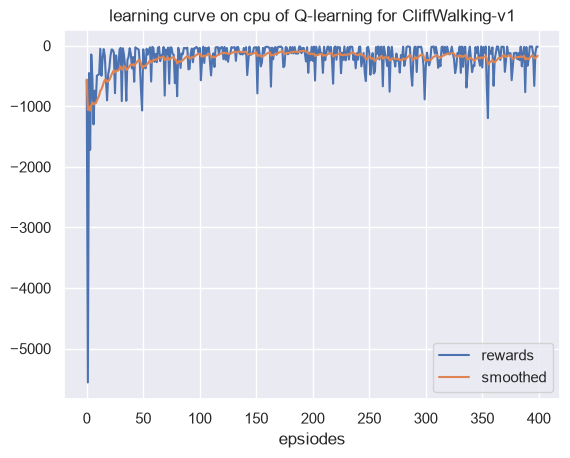

In [57]:
plot_rewards(train_rewards, cfg, tag="train")

### 3.5.5 开始测试

In [58]:
print('开始测试！')
print(f'环境：{cfg.env_name}, 算法：{cfg.algo_name}, 设备：{cfg.device}')
test_rewards = []  # 记录所有回合的奖励
for i_ep in range(cfg.test_eps):
    ep_reward = 0  # 记录每个episode的reward
    state, _ = env.reset()  # 重置环境, 重新开一局（即开始新的一个回合）
    print(i_ep)
    while True:
        action = agent.predict(state)  # 根据算法选择一个动作
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
#         env.render() #windows 平台的同学和Linux有外界显示器的，可以尝试渲染
        state = next_state  # 更新状态
        ep_reward += reward
        if done:
            break
    test_rewards.append(ep_reward)
    print(f"回合数：{i_ep+1}/{cfg.test_eps}, 奖励：{ep_reward:.1f}")
print('完成测试！')

开始测试！
环境：CliffWalking-v1, 算法：Q-learning, 设备：cpu
0
回合数：1/20, 奖励：-13.0
1
回合数：2/20, 奖励：-13.0
2
回合数：3/20, 奖励：-13.0
3
回合数：4/20, 奖励：-13.0
4
回合数：5/20, 奖励：-13.0
5
回合数：6/20, 奖励：-13.0
6
回合数：7/20, 奖励：-13.0
7
回合数：8/20, 奖励：-13.0
8
回合数：9/20, 奖励：-13.0
9
回合数：10/20, 奖励：-13.0
10
回合数：11/20, 奖励：-13.0
11
回合数：12/20, 奖励：-13.0
12
回合数：13/20, 奖励：-13.0
13
回合数：14/20, 奖励：-13.0
14
回合数：15/20, 奖励：-13.0
15
回合数：16/20, 奖励：-13.0
16
回合数：17/20, 奖励：-13.0
17
回合数：18/20, 奖励：-13.0
18
回合数：19/20, 奖励：-13.0
19
回合数：20/20, 奖励：-13.0
完成测试！


### 3.5.6 画出测试结果

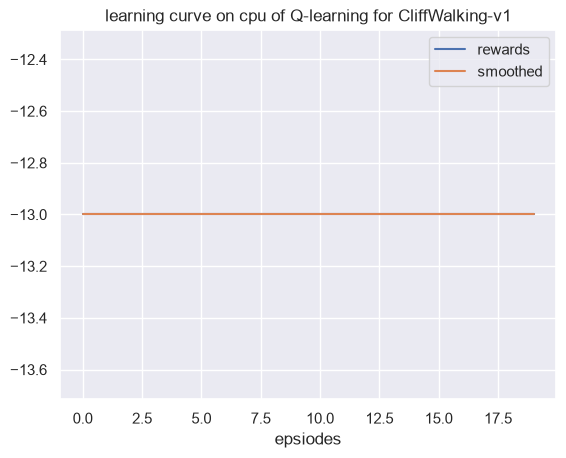

In [59]:
plot_rewards(test_rewards, cfg, tag="test")  # 画出结果

## 4. 问题

**Q1&2：** Q-learning 和 SARSA的区别？从训练结果中你有什么样的发现？为什么训练结果会有这些不同？为什么在测试阶段的最终结果有所差异？

SARSA 是 on-policy 算法，使用当前行为策略实际选出的下一个动作 $a'$ :

$$
Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma Q(s',a')-Q(s,a)\right]
$$

实验中，$a'$ 由$\epsilon$-greedy 策略采样，因此更新过程会考虑随机探索可能带来的影响。

Q-learning 是 off-policy 算法。使用下一状态所有动作中的最大 $Q$ 值进行更新：

$$
Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\right]
$$

更新目标直接按照下一步选择最优动作计算，不考虑实际探索带来的风险。

对比两个实验的曲线可以注意到：

- SARSA在前 50 个回合内奖励迅速上升并收敛。到了训练中后期（如 200~400 回合），大多数单回合奖励稳定在 $-17.0$ 到 $-35.0$ 之间，平滑曲线（smoothed）贴近 0 轴下方（约 $-30$ 左右），偶发掉入悬崖的次数较少（下探尖峰多在 $-120$ 到 $-250$ 之间）。
- Q-learning虽然收敛速度同样很快，但在整个训练周期内，单回合奖励（蓝线 rewards）的震荡幅度显著大于 SARSA，频繁出现跌落至 $-500$ 甚至 $-1000$ 以下 的剧烈负奖励尖峰，导致其平滑奖励曲线（smoothed）整体低于 SARSA（在 $-100$ 到 $-200$ 附近波动）。 

训练阶段，SARSA 的回报总体更高，后期波动也较小；Q-learning 仍然频繁出现较大的负回报。这与训练时固定使用 $\epsilon=0.3$ 有关：即使已经学到较好的策略，智能体仍会持续探索。

SARSA 的更新考虑了探索动作的后果。靠近悬崖行走时，随机动作可能导致坠崖并获得 $-100$ 的奖励，因此 SARSA 倾向学习远离悬崖、步数稍多的安全路线。Q-learning 的更新则按照未来选择最优动作计算，倾向学习贴近悬崖的最短路线；但实际训练仍有随机探索，因此更容易坠崖，导致训练回报较低、波动较大。

测试阶段，两种算法都调用 `predict()`, 直接采取确定性的纯贪心策略，直接选择 $Q$ 值最大的动作，不再随机探索。Q-learning 因而能够沿最短路线用 13 步到达终点，获得 $-13$ 的回报；本次 SARSA 学到的贪心路线需要 17 步，回报为 $-17$。测试时取消探索不会重新学习 $Q$ 值，因此 SARSA 仍然保留训练过程中形成的安全绕行策略。

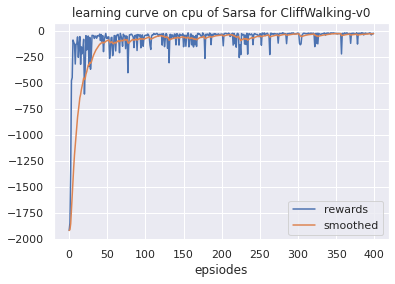

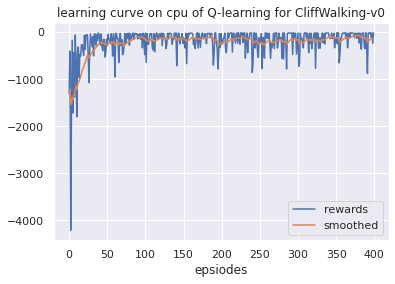

**Q3：** $\epsilon$的大小对于实验结果的影响？你觉得如何调整较为合适？

$\epsilon$ 控制 $\epsilon$-greedy 策略中的探索程度。$\epsilon$ 较大时，智能体能够尝试更多状态和动作，有利于早期探索，但也会增加无效移动和坠崖的次数，使训练回报降低、波动增大。$\epsilon$ 较小时，智能体更多地利用已经学到的策略，通常有利于后期稳定表现，但如果训练初期就设置得过小，可能因探索不足而无法找到更好的路线。

$\epsilon$ 对两种算法的影响也有所不同。SARSA 使用实际采样的下一动作更新，因此 $\epsilon$ 会影响它所学习的策略：探索越频繁，悬崖附近的风险越大，通常越倾向于安全绕行。Q-learning 的更新目标始终使用下一状态的最大 $Q$ 值，但 $\epsilon$ 仍会影响训练数据的采集和实际训练回报。本实验固定使用 $\epsilon=0.3$，因此训练后期依然存在较多随机探索，尤其容易使沿悬崖行走的 Q-learning 智能体坠崖。

较合适的方法是在训练初期保留较多探索，随后逐步减小 $\epsilon$。例如，可以尝试按回合进行衰减：

$$
\epsilon_k=\max\left(0.01,\;0.3\times0.99^k\right)
$$

其中 $k$ 从 0 开始表示训练回合编号。这样初期可以充分探索，后期则更多地利用已有经验，同时保留少量探索机会。这只是可尝试的设置，具体衰减速度需要结合训练回报、测试路径和多个随机种子的结果进行比较。

**Q4：** 折扣因子的大小是否会对训练结果产生影响？为什么会出现这种影响？

会。折扣因子 $\gamma$ 决定智能体对未来奖励的重视程度，因此会影响 SARSA 和 Q-learning 的 $Q$ 值更新及学习结果。

当 $\gamma$ 较小时，智能体更关注即时奖励。但悬崖寻路中大多数正常动作的奖励都是 $-1$，过小的 $\gamma$ 会使智能体难以区分动作的长期价值，也难以充分考虑之后的坠崖风险。当 $\gamma$ 较大时，智能体更重视未来的累计奖励，有利于考虑完整路径的代价，但也可能放大后续 $Q$ 值估计误差的影响，并非越大越好。

本实验使用 $\gamma=0.9$。调整它可能影响训练速度、回报波动和最终策略，但不一定改变最优路线。可以在其他参数相同的条件下，对比不同 $\gamma$ 的训练与测试结果。

## 5. 提交形式

* 提交notebook**原始文件**， 即以.ipynb为结尾的文件

* 本次实验notebook的**pdf**


* pdf转换方法：
    1. 在当前页面浏览器右上角选择“打印...”
    2. 目标打印机选择“另存为PDF”，布局选择“纵向”。然后查看预览效果，主要查看是否有代码内容显示不全，若无，则按“保存”即可，否则，继续选择下面的“缩放”，直到预览的结果满意为止，最后点击“保存”即可。